# Permutation test for cohort separability, step by step

**Question:** For a probe adapted on a source cohort *s*, are targets *t* whose scans are more separable from *s* also the targets where the AD probe transfers worse?

**Data.** `results_updated/full_pipeline/full_pipeline_all.csv`: 5 FMs × 30 source→target pairs × 20 splits = 3,000 rows.

**Procedure.**
1. Average each (FM, source, target) over the 20 splits → two 6 × 6 tables per FM: separability **X** and external AUC **Y**.
2. For each FM *m* and source *s*: Spearman ρ(m, s) between row *s* of X and row *s* of Y (the 5 targets).
3. Test statistic: ρ̄ = mean of the 30 ρ(m, s).
4. Null distribution: relabel the 6 cohorts with a permutation π, on rows **and** columns of X together, the same π for all FMs; Y untouched. Recompute ρ̄.
5. Do this for all 6! = 720 permutations → exact p-value.

Then: the same test for the other statistics and for the 10 indicators, and one figure per step for the slides.
All figures are saved as PNG (for slides) and PDF (for the paper) in `local/output_v2/figures_permutation/`.

In [18]:
import itertools
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from scipy.stats import rankdata

REPO = Path(os.environ.get("REPO", "/home/kmouheb/Documents/GitLab/cross-cohort-fm-finetuning"))
DATA = REPO / "local" / "output" / "combined_cohort_disease_results_with_jsd_prev.csv"
META = REPO / "features" / "metadata" / "meta_info_used_samples.csv"
FIG = REPO / "local" / "output_v2" / "figures_permutation"
FIG.mkdir(parents=True, exist_ok=True)

# Fixed orders and labels (cohort order = row/column order of every table)
COHORTS = ["ADNI", "OASIS3", "OASIS4", "AIBL", "BrainLAT", "NigerianBrain"]
SHORT = {"ADNI": "ADNI", "OASIS3": "OAS-3", "OASIS4": "OAS-4", "AIBL": "AIBL", "BrainLAT": "BLat", "NigerianBrain": "NB"}
MODELS = ["SAM-Med3D", "BrainIAC", "3DINO", "Med-SAM2", "Medical-SAM2"]
MODEL_LABEL = {"3DINO": "3DINO", "BrainIAC": "BrainIAC", "Medical-SAM2": "Medical-SAM2", "Med-SAM2": "Med-SAM2", "SAM-Med3D": "SAM-Med3D"}

# Example used in the step-by-step figures
EXAMPLE_FM = "BrainIAC"
EXAMPLE_SOURCE = "ADNI"
EXAMPLE_PERM = (2, 4, 0, 1, 5, 3)  # any permutation of range(6); index i takes the values of cohort EXAMPLE_PERM[i]

# Style (slide-size fonts)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
FM_COLOR = dict(zip(MODELS, SERIES))
INK, INK2, GRID = "#14213D", "#52514e", "#e4e3df"
BLUES = LinearSegmentedColormap.from_list("b", ["#eef4fc", "#9cc0ee", "#2a78d6", "#12408a"])
ORANGES = LinearSegmentedColormap.from_list("o", ["#fdf1ea", "#f5b48f", "#eb6834", "#9a3a12"])
plt.rcParams.update({"font.size": 15, "axes.edgecolor": INK2, "axes.labelcolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "pdf.fonttype": 42})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=200)
    fig.savefig(FIG / f"{name}.pdf")
    plt.show()

In [19]:
df['model'].value_counts()

model
SAM-Med3D       600
BrainIAC        600
3DINO           600
Med-SAM2        600
Medical-SAM2    600
Name: count, dtype: int64

## 0. Load and check the data

In [20]:
df = pd.read_csv(DATA)
print(df.shape)
counts = df.groupby(["model", "train", "test"]).size()
print("combinations:", len(counts), "| splits per combination:", counts.unique())
assert set(df.model) == set(MODELS) and set(df.train) == set(COHORTS) and (df.train != df.test).all()
df.head()

(3000, 20)
combinations: 150 | splits per combination: [20]


,index,experiment,split,balanced_accuracy_cohort,f1_score_cohort,auc_cohort,model,train,test,balanced_accuracy_disease,f1_score_disease,auc_disease,wasserstein_dist,train_size,test_size,id,scanner_jsd,field_jsd,prevalence_jsd,combination
0,0,ADNI_AIBL,0,0.666667,0.671053,0.676800,SAM-Med3D,ADNI,AIBL,0.735787,0.424528,0.802012,0.016004,931,355,0_SAM-Med3D_ADNI_AIBL,0.3151,0.0345,0.0716,ADNI_AIBL_SAM-Med3D
1,1,ADNI_AIBL,1,0.653333,0.720430,0.705244,SAM-Med3D,ADNI,AIBL,0.710327,0.448980,0.761027,0.016478,931,355,1_SAM-Med3D_ADNI_AIBL,0.3151,0.0345,0.0716,ADNI_AIBL_SAM-Med3D
2,2,ADNI_AIBL,2,0.593333,0.655367,0.644444,SAM-Med3D,ADNI,AIBL,0.657378,0.410714,0.794889,0.016406,931,355,2_SAM-Med3D_ADNI_AIBL,0.3151,0.0345,0.0716,ADNI_AIBL_SAM-Med3D
3,3,ADNI_AIBL,3,0.573333,0.632184,0.622400,SAM-Med3D,ADNI,AIBL,0.733819,0.450867,0.777583,0.016390,931,355,3_SAM-Med3D_ADNI_AIBL,0.3151,0.0345,0.0716,ADNI_AIBL_SAM-Med3D
4,4,ADNI_AIBL,4,0.593333,0.621118,0.630756,SAM-Med3D,ADNI,AIBL,0.681182,0.393258,0.710983,0.016388,931,355,4_SAM-Med3D_ADNI_AIBL,0.3151,0.0345,0.0716,ADNI_AIBL_SAM-Med3D


## 1. Two 6 × 6 tables per FM

Average over the 20 splits. X(s, t) = separability (cohort-probe AUC, normative scans); Y(s, t) = external AD AUC of the probe adapted on s, evaluated on t. The diagonal is empty.

In [21]:
cell = df.groupby(["model", "train", "test"], as_index=False).mean(numeric_only=True)

def tables(col):
    """FM -> 6x6 array (rows = source, columns = target, diagonal = NaN)."""
    return {m: g.pivot(index="train", columns="test", values=col).reindex(index=COHORTS, columns=COHORTS).to_numpy()
            for m, g in cell.groupby("model")}

X = tables("auc_cohort")
Y = tables("auc_disease")
pd.DataFrame(X[EXAMPLE_FM], index=COHORTS, columns=COHORTS).round(2)

,ADNI,OASIS3,OASIS4,AIBL,BrainLAT,NigerianBrain
ADNI,NaN,0.63,0.60,0.65,0.91,0.96
OASIS3,0.63,NaN,0.59,0.64,0.86,0.94
OASIS4,0.60,0.59,NaN,0.70,0.90,0.96
AIBL,0.65,0.64,0.70,NaN,0.80,0.92
BrainLAT,0.91,0.86,0.90,0.80,NaN,0.81
NigerianBrain,0.96,0.94,0.96,0.92,0.81,NaN


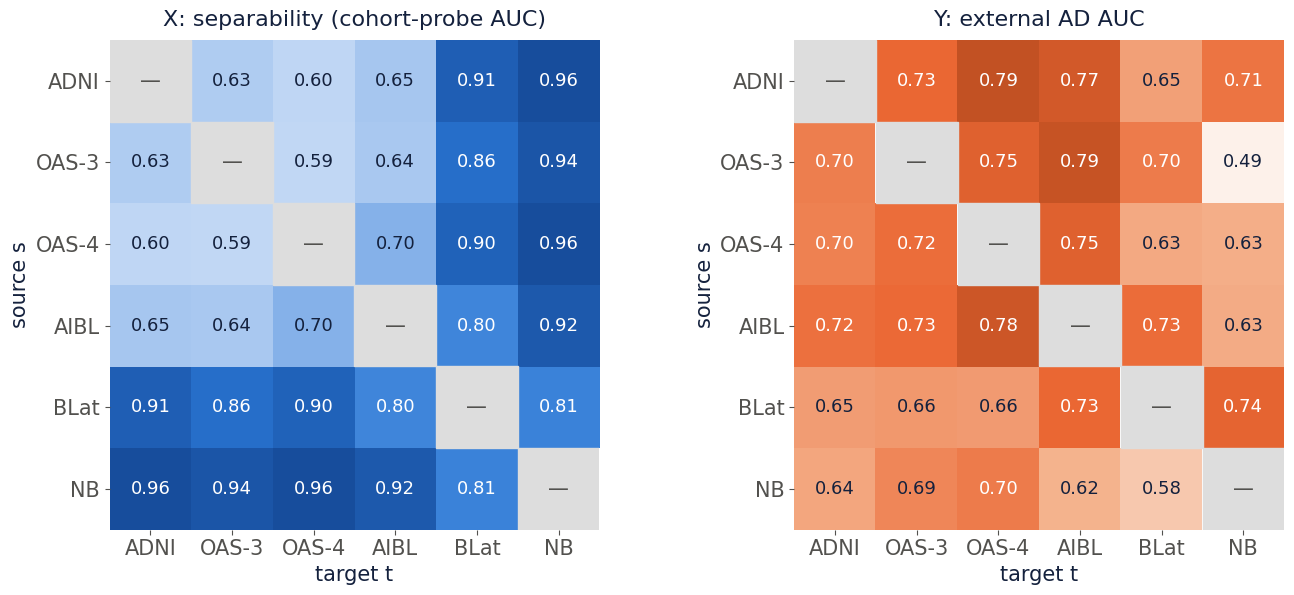

In [22]:
def heat(ax, A, cmap, title, vmin, vmax, rowlabels=None, collabels=None, highlight_row=None):
    ax.imshow(np.ma.masked_invalid(A), cmap=cmap, vmin=vmin, vmax=vmax)
    for i in range(6):
        for j in range(6):
            if np.isnan(A[i, j]):
                ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, color="#dddddd"))
                ax.text(j, i, "—", ha="center", va="center", color=INK2)
                continue
            dark = (A[i, j] - vmin) / (vmax - vmin) > 0.55
            ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center", fontsize=13, color="white" if dark else INK)
    labels = [SHORT[c] for c in COHORTS]
    ax.set_xticks(range(6)); ax.set_xticklabels(collabels or labels)
    ax.set_yticks(range(6)); ax.set_yticklabels(rowlabels or labels)
    ax.set_xlabel("target t"); ax.set_ylabel("source s")
    ax.set_title(title, fontsize=16, color=INK, pad=10)
    for sp in ax.spines.values():
        sp.set_visible(False)
    if highlight_row is not None:
        ax.add_patch(Rectangle((-.5, highlight_row - .5), 6, 1, fill=False, lw=3, ec=INK))

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
heat(axes[0], X[EXAMPLE_FM], BLUES, "X: separability (cohort-probe AUC)", 0.5, 1.0)
heat(axes[1], Y[EXAMPLE_FM], ORANGES, "Y: external AD AUC", 0.5, 0.85)
save(fig, "step1_tables")

## 2. One source, one correlation

For the probe adapted on the example source, rank-correlate separability and external AUC across its 5 targets:

ρ(m, s) = Spearman( X_m(s, ·), Y_m(s, ·) )

BrainIAC, source ADNI: rho = -0.80


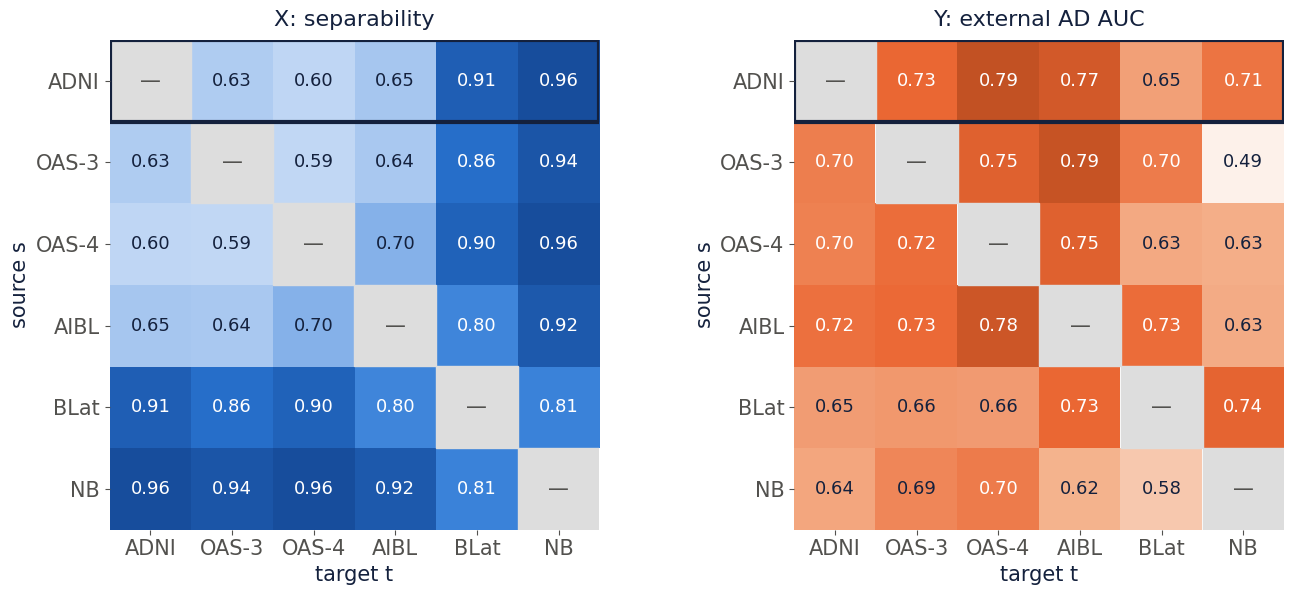

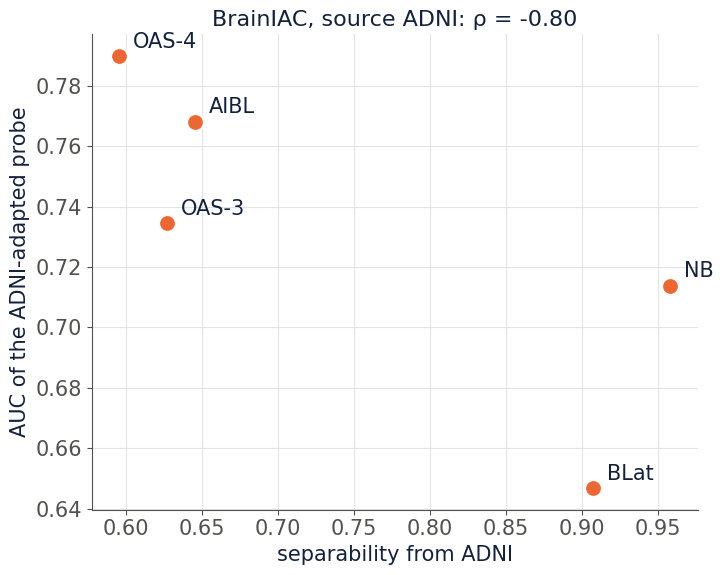

In [23]:
s = COHORTS.index(EXAMPLE_SOURCE)
targets = [t for t in range(6) if t != s]
x, y = X[EXAMPLE_FM][s, targets], Y[EXAMPLE_FM][s, targets]

def spearman(a, b):
    return np.corrcoef(rankdata(a), rankdata(b))[0, 1]

rho_example = spearman(x, y)
print(f"{MODEL_LABEL[EXAMPLE_FM]}, source {EXAMPLE_SOURCE}: rho = {rho_example:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
heat(axes[0], X[EXAMPLE_FM], BLUES, "X: separability", 0.5, 1.0, highlight_row=s)
heat(axes[1], Y[EXAMPLE_FM], ORANGES, "Y: external AD AUC", 0.5, 0.85, highlight_row=s)
save(fig, "step2a_row_highlight")

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(x, y, s=160, color=FM_COLOR[EXAMPLE_FM], edgecolor="white", lw=2, zorder=3)
for xi, yi, t in zip(x, y, targets):
    ax.annotate(SHORT[COHORTS[t]], (xi, yi), xytext=(10, 6), textcoords="offset points", fontsize=15, color=INK)
ax.set_xlabel(f"separability from {SHORT[EXAMPLE_SOURCE]}")
ax.set_ylabel(f"AUC of the {SHORT[EXAMPLE_SOURCE]}-adapted probe")
ax.set_title(f"{MODEL_LABEL[EXAMPLE_FM]}, source {SHORT[EXAMPLE_SOURCE]}: ρ = {rho_example:.2f}", fontsize=16, color=INK)
ax.grid(color=GRID)
save(fig, "step2b_row_scatter")

## 3. The test statistic

Repeat for every FM and every source (5 × 6 = 30 correlations) and average: ρ̄ = (1/30) Σ ρ(m, s).

The functions below are vectorised so that step 5 (720 relabellings) runs in seconds. Spearman is Pearson on ranks, with ties given their average rank; the empty diagonal is dropped from each row.

In [24]:
OFF = np.array([[j for j in range(6) if j != i] for i in range(6)])  # (6, 5): off-diagonal column indices per row

def stack(tab):
    return np.stack([tab[m] for m in MODELS])  # (5 FMs, 6, 6)

def row_spearman(A, B):
    """Spearman per (FM, row) across the 5 off-diagonal entries. A, B: (5, 6, 6) -> (5, 6)."""
    a = rankdata(A[:, np.arange(6)[:, None], OFF], axis=-1)
    b = rankdata(B[:, np.arange(6)[:, None], OFF], axis=-1)
    a = a - a.mean(-1, keepdims=True); b = b - b.mean(-1, keepdims=True)
    den = np.sqrt((a ** 2).sum(-1) * (b ** 2).sum(-1))
    with np.errstate(invalid="ignore", divide="ignore"):
        return (a * b).sum(-1) / den  # NaN if a row is constant (e.g. a source-only indicator)

def double_center(A):
    return A - np.nanmean(A, 2, keepdims=True) - np.nanmean(A, 1, keepdims=True) + np.nanmean(A, (1, 2), keepdims=True)

def pooled_spearman(A, B):
    """Classic Mantel-style statistic: Spearman over all 30 off-diagonal cells, per FM -> (5,)."""
    off = ~np.eye(6, dtype=bool)
    out = []
    for a, b in zip(A, B):
        a, b = a[off], b[off]
        out.append(np.nan if a.std() == 0 else np.corrcoef(rankdata(a), rankdata(b))[0, 1])
    return np.array(out)

def statistics(A, B):
    """All four statistics, each averaged over FMs (and rows where relevant)."""
    return {
        "within_source": np.nanmean(row_spearman(A, B)),                                     # primary
        "within_target": np.nanmean(row_spearman(A.transpose(0, 2, 1), B.transpose(0, 2, 1))),
        "pooled": np.nanmean(pooled_spearman(A, B)),
        "interaction": np.nanmean(pooled_spearman(double_center(A), double_center(B))),
    }

XA, YA = stack(X), stack(Y)
rho_ms = row_spearman(XA, YA)  # (5 FMs, 6 sources)
rho_bar = np.nanmean(rho_ms)
print(f"observed rho-bar = {rho_bar:.3f}")
print(f"negative: {(rho_ms < 0).sum()}, zero: {(rho_ms == 0).sum()}, positive: {(rho_ms > 0).sum()} of {rho_ms.size}")
pd.DataFrame(rho_ms, index=[MODEL_LABEL[m] for m in MODELS], columns=COHORTS).round(2)

observed rho-bar = -0.436
negative: 23, zero: 1, positive: 6 of 30


,ADNI,OASIS3,OASIS4,AIBL,BrainLAT,NigerianBrain
SAM-Med3D,0.1,-0.6,-0.8,-0.6,-0.3,0.40
BrainIAC,-0.8,-0.5,-0.7,-0.5,-0.9,0.70
3DINO,-0.9,-0.9,0.3,0.5,0.4,-0.67
Med-SAM2,-0.9,-0.7,-0.9,-0.9,-0.3,0.00
Medical-SAM2,-1.0,-0.4,-0.8,-0.4,-0.9,-0.10


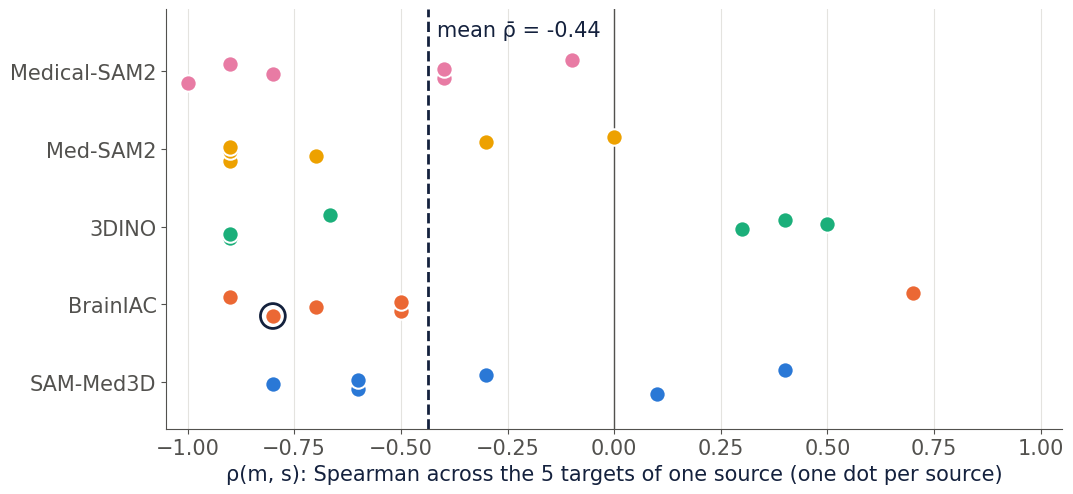

In [25]:
fig, ax = plt.subplots(figsize=(11, 5.2))
for i, m in enumerate(MODELS):
    yy = i + np.linspace(-0.15, 0.15, 6)  # small vertical offsets so tied values stay visible
    ax.scatter(rho_ms[i], yy, s=140, color=FM_COLOR[m], edgecolor="white", lw=1.5, zorder=3)
    if m == EXAMPLE_FM:
        ax.scatter(rho_ms[i, s], yy[s], s=320, facecolor="none", edgecolor=INK, lw=2, zorder=4)
ax.axvline(rho_bar, color=INK, lw=2, ls="--")
ax.text(rho_bar + 0.02, 4.45, f"mean ρ̄ = {rho_bar:.2f}", fontsize=15, color=INK)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(range(5)); ax.set_yticklabels([MODEL_LABEL[m] for m in MODELS])
ax.set_xlim(-1.05, 1.05); ax.set_ylim(-0.6, 4.8)
ax.set_xlabel("ρ(m, s): Spearman across the 5 targets of one source (one dot per source)")
ax.grid(axis="x", color=GRID)
save(fig, "step3_all_rhos")

## 4. One relabelling

Pick a permutation π of the 6 cohorts and relabel X on rows **and** columns: X^π(s, t) = X(π(s), π(t)). The same π is used for all 5 FMs (they share the same cohorts). Y is not touched. Each relabelled row is still a real row of separabilities, so the structure of X is kept; only its link to Y is broken.

relabelling: ADNI <- OAS-4, OAS-3 <- BLat, OAS-4 <- ADNI, AIBL <- OAS-3, BLat <- NB, NB <- AIBL
rho-bar under this relabelling = -0.098


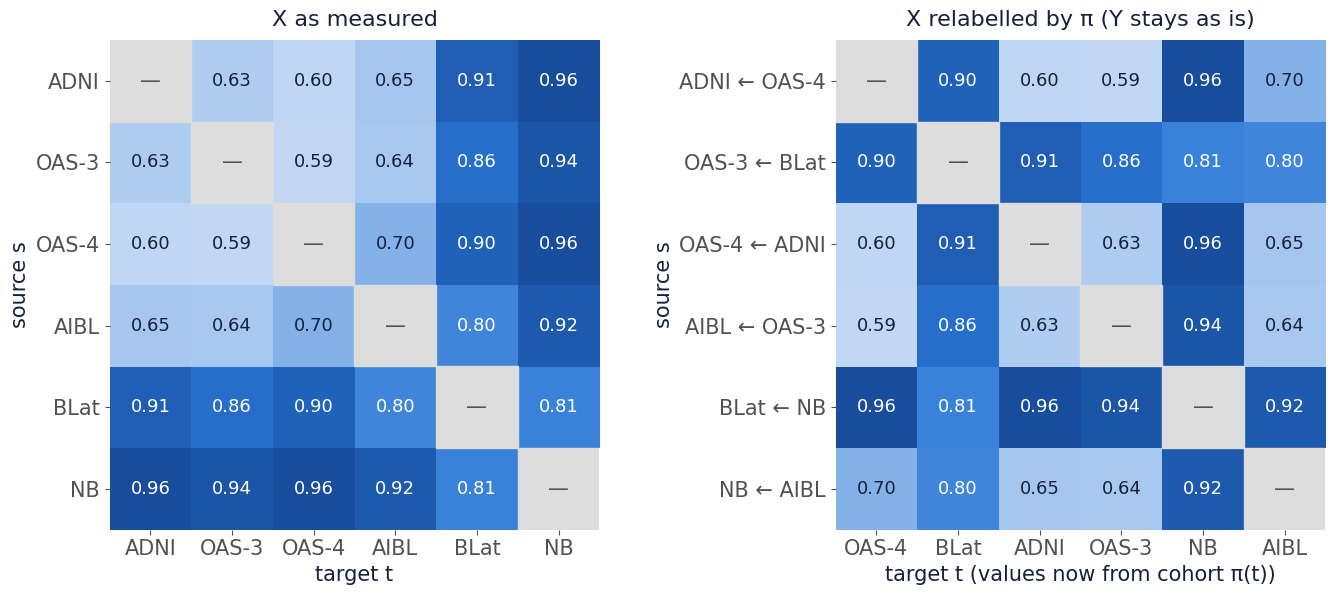

In [26]:
perm = np.array(EXAMPLE_PERM)
XA_perm = XA[:, perm][:, :, perm]
stat_perm = np.nanmean(row_spearman(XA_perm, YA))
print("relabelling:", ", ".join(f"{SHORT[COHORTS[i]]} <- {SHORT[COHORTS[perm[i]]]}" for i in range(6)))
print(f"rho-bar under this relabelling = {stat_perm:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
heat(axes[0], X[EXAMPLE_FM], BLUES, "X as measured", 0.5, 1.0)
heat(axes[1], XA_perm[MODELS.index(EXAMPLE_FM)], BLUES, "X relabelled by π (Y stays as is)", 0.5, 1.0,
     rowlabels=[f"{SHORT[COHORTS[i]]} ← {SHORT[COHORTS[perm[i]]]}" for i in range(6)],
     collabels=[SHORT[COHORTS[perm[j]]] for j in range(6)])
axes[1].set_xlabel("target t (values now from cohort π(t))")
save(fig, "step4_relabel")

## 5. All 720 relabellings → exact p-value

p = #{π : |ρ̄(π)| ≥ |ρ̄_obs|} / 720 (two-sided). The identity is one of the 720, so the smallest possible p is 1/720 ≈ 0.0014.

In [27]:
PERMS = np.array(list(itertools.permutations(range(6))))  # (720, 6)

def null_distribution(A, B, stat="within_source"):
    return np.array([statistics(A[:, p][:, :, p], B)[stat] for p in PERMS])

def perm_p(obs, null, eps=1e-12):
    null = null[~np.isnan(null)]
    return {"p_two_sided": np.mean(np.abs(null) >= abs(obs) - eps),
            "p_one_sided_neg": np.mean(null <= obs + eps),
            "n_as_extreme": int(np.sum(np.abs(null) >= abs(obs) - eps)), "n_perm": len(null)}

null = null_distribution(XA, YA)
res = perm_p(rho_bar, null)
print(f"observed {rho_bar:.3f} | {res['n_as_extreme']} of {res['n_perm']} relabellings as extreme | "
      f"p (two-sided) = {res['p_two_sided']:.4f} | p (one-sided) = {res['p_one_sided_neg']:.4f}")

observed -0.436 | 3 of 720 relabellings as extreme | p (two-sided) = 0.0042 | p (one-sided) = 0.0042


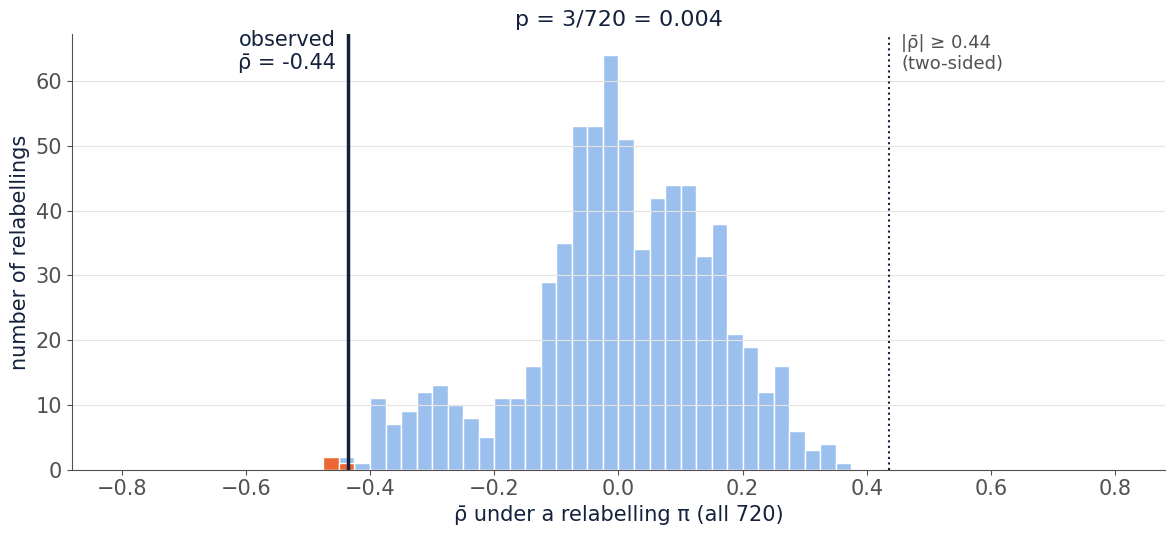

In [28]:
fig, ax = plt.subplots(figsize=(12, 5.6))
bins = np.linspace(-0.8, 0.8, 65)
extreme = np.abs(null) >= abs(rho_bar) - 1e-12
ax.hist(null, bins=bins, color="#9cc0ee", edgecolor="white")
ax.hist(null[extreme], bins=bins, color=SERIES[1], edgecolor="white")
ax.axvline(rho_bar, color=INK, lw=2.5)
ax.axvline(-rho_bar, color=INK, lw=1.5, ls=":")
top = ax.get_ylim()[1]
ax.text(rho_bar - 0.02, top * 0.92, f"observed\nρ̄ = {rho_bar:.2f}", ha="right", fontsize=15, color=INK)
ax.text(-rho_bar + 0.02, top * 0.92, f"|ρ̄| ≥ {abs(rho_bar):.2f}\n(two-sided)", ha="left", fontsize=13, color=INK2)
ax.set_xlabel("ρ̄ under a relabelling π (all 720)")
ax.set_ylabel("number of relabellings")
ax.set_title(f"p = {res['n_as_extreme']}/720 = {res['p_two_sided']:.3f}", fontsize=16, color=INK)
ax.grid(axis="y", color=GRID)
save(fig, "step5_null_distribution")

## 6. Why relabel whole cohorts?

Compare with a naive null that shuffles the 30 off-diagonal cells of X independently (as if the cells were independent). It ignores that pairs sharing a cohort are correlated, so its null is too narrow and its p-value too small.

null SD: cell shuffling 0.091 vs cohort relabelling 0.156
p: cell shuffling 0.00005 vs cohort relabelling 0.0042


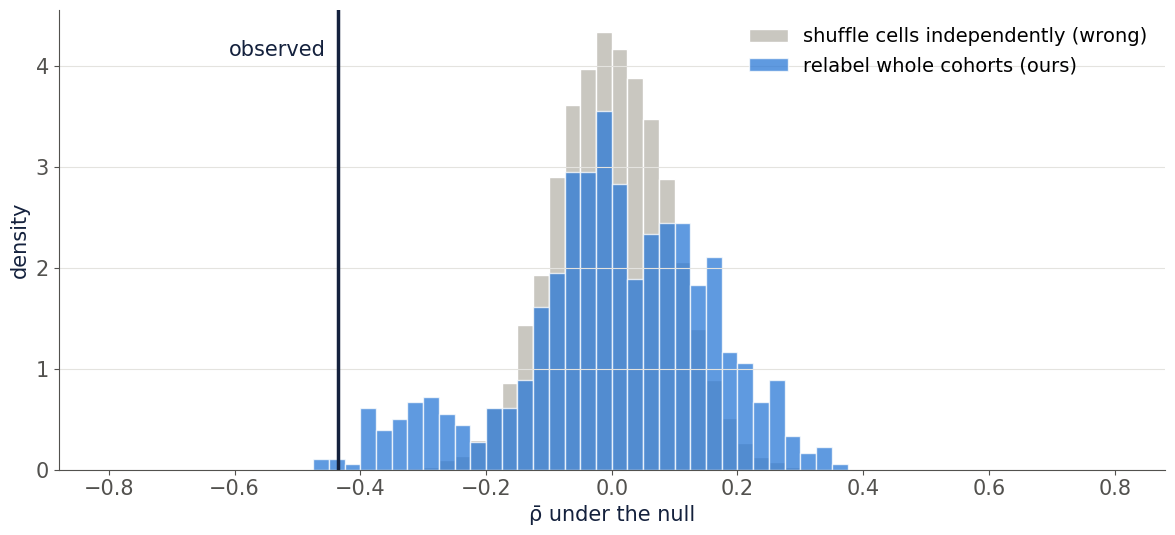

In [29]:
rng = np.random.default_rng(0)
off = ~np.eye(6, dtype=bool)
naive = []
for _ in range(20000):
    A = XA.copy()
    for k in range(len(MODELS)):
        v = A[k][off]; A[k][off] = rng.permutation(v)
    naive.append(np.nanmean(row_spearman(A, YA)))
naive = np.array(naive)
p_naive = (np.sum(np.abs(naive) >= abs(rho_bar)) + 1) / (len(naive) + 1)
print(f"null SD: cell shuffling {naive.std():.3f} vs cohort relabelling {null.std():.3f}")
print(f"p: cell shuffling {p_naive:.5f} vs cohort relabelling {res['p_two_sided']:.4f}")

fig, ax = plt.subplots(figsize=(12, 5.6))
ax.hist(naive, bins=bins, density=True, color="#c9c7c0", edgecolor="white", label="shuffle cells independently (wrong)")
ax.hist(null, bins=bins, density=True, color=SERIES[0], alpha=0.75, edgecolor="white", label="relabel whole cohorts (ours)")
ax.axvline(rho_bar, color=INK, lw=2.5)
ax.text(rho_bar - 0.02, ax.get_ylim()[1] * 0.9, "observed", ha="right", fontsize=15, color=INK)
ax.set_xlabel("ρ̄ under the null"); ax.set_ylabel("density")
ax.legend(frameon=False, fontsize=14, loc="upper right"); ax.grid(axis="y", color=GRID)
save(fig, "step6_naive_vs_cohort_null")

## 7. The other statistics, same 720 relabellings

* **within_source** (primary): rank the 5 targets of a fixed model.
* **within_target**: rank the 5 candidate sources for a fixed target.
* **pooled**: classic Mantel statistic, Spearman over all 30 cells per FM.
* **interaction**: pooled after double-centering both tables (removes source and target main effects).

In [30]:
obs_all = statistics(XA, YA)
rows = []
for stat, obs in obs_all.items():
    nd = null_distribution(XA, YA, stat)
    rows.append({"statistic": stat, "observed": obs, **perm_p(obs, nd)})
stats_table = pd.DataFrame(rows)
stats_table.to_csv(FIG / "statistics_cohort_probe.csv", index=False)
stats_table.round(4)

,statistic,observed,p_two_sided,p_one_sided_neg,n_as_extreme,n_perm
0,within_source,-0.4356,0.0042,0.0042,3,720
1,within_target,-0.5555,0.0125,0.0125,9,720
2,pooled,-0.6475,0.0028,0.0028,2,720
3,interaction,-0.4455,0.0056,0.0056,4,720


## 8. The 10 indicators (+ prevalence oracle)

Same procedure for every indicator. Feature divergences: one per family of two-sample measures. Metadata: acquisition and demographic JSDs. Source-side values are constant within a source, so they have no within-source score. AD-prevalence JSD needs target labels, so it is an oracle only.

In [31]:
# adaptation-set size = number of scans in the source cohort
n_total = pd.read_csv(META).groupby("cohort").size()
cell["n_train"] = cell["train"].map(n_total)

INDICATORS = {
    "auc_cohort": ("Cohort probe AUC (ours)", "probe"),
    "mmd2": ("MMD² (kernel)", "feature divergence"),
    "frechet_dist": ("Fréchet distance (Gaussian)", "feature divergence"),
    "wasserstein_rel": ("Relative W2 (optimal transport)", "feature divergence"),
    "jsd_manufacturer": ("JSD manufacturer", "metadata"),
    "jsd_field_strength": ("JSD field strength", "metadata"),
    "jsd_sex": ("JSD sex", "metadata"),
    "wasserstein_age": ("W1 age (years)", "metadata"),
    "n_train": ("Adaptation-set size", "source only"),
    "auc_disease_internal": ("Source internal AUC", "source only"),
    "jsd_label": ("JSD AD prevalence (oracle)", "oracle"),
}

rows = []
for col, (label, family) in INDICATORS.items():
    A = stack(tables(col))
    obs = statistics(A, YA)
    row = {"indicator": col, "label": label, "family": family}
    for stat in ["within_source", "within_target"]:
        row[stat] = obs[stat]
        if not np.isnan(obs[stat]):
            row[f"p_{stat}"] = perm_p(obs[stat], null_distribution(A, YA, stat))["p_two_sided"]
    rows.append(row)
bench = pd.DataFrame(rows)
bench.to_csv(FIG / "indicator_benchmark.csv", index=False)
bench.round(3)

KeyError: 'mmd2'

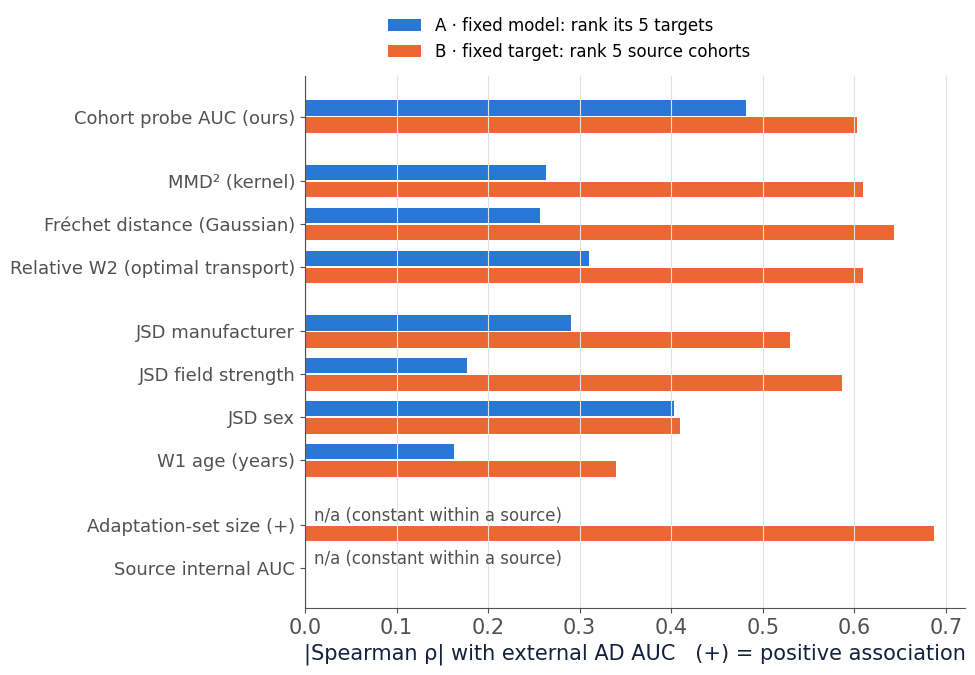

In [14]:
b = bench[bench.family != "oracle"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(b))[::-1].astype(float)
for start in [1, 4, 8]:   # gaps between families
    y[start:] -= 0.5
ax.barh(y + 0.2, b.within_source.abs(), 0.36, color=SERIES[0], label="A · fixed model: rank its 5 targets")
ax.barh(y - 0.2, b.within_target.abs(), 0.36, color=SERIES[1], label="B · fixed target: rank 5 source cohorts")
for yi, v in zip(y, b.within_source):
    if np.isnan(v):
        ax.text(0.01, yi + 0.2, "n/a (constant within a source)", va="center", fontsize=12, color=INK2)
labels = [l + (" (+)" if v > 0 else "") for l, v in zip(b.label, b.within_target)]
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=13)
ax.axvline(0, color=INK2, lw=0.8)
ax.set_xlabel("|Spearman ρ| with external AD AUC   (+) = positive association")
ax.legend(frameon=False, fontsize=12, loc="lower center", bbox_to_anchor=(0.4, 1.0))
ax.grid(axis="x", color=GRID)
save(fig, "step8_indicator_benchmark")

## 9. Summary

Numbers to quote on the slides and in the paper.

In [15]:
print(f"Within-source Spearman, cohort probe: rho-bar = {rho_bar:.2f}; "
      f"{res['n_as_extreme']}/720 relabellings as extreme; p = {res['p_two_sided']:.3f} (two-sided), "
      f"{res['p_one_sided_neg']:.3f} (one-sided)")
print(f"Naive cell-shuffling would give p = {p_naive:.5f} (null SD {naive.std():.2f} vs {null.std():.2f})")
print("Figures written to", FIG)
sorted(p.name for p in FIG.iterdir())

Within-source Spearman, cohort probe: rho-bar = -0.48; 7/720 relabellings as extreme; p = 0.010 (two-sided), 0.003 (one-sided)
Naive cell-shuffling would give p = 0.00005 (null SD 0.09 vs 0.21)
Figures written to /home/kmouheb/Documents/GitLab/cross-cohort-fm-finetuning/local/output_v2/figures_permutation


['indicator_benchmark.csv',
 'statistics_cohort_probe.csv',
 'step1_tables.pdf',
 'step1_tables.png',
 'step2a_row_highlight.pdf',
 'step2a_row_highlight.png',
 'step2b_row_scatter.pdf',
 'step2b_row_scatter.png',
 'step3_all_rhos.pdf',
 'step3_all_rhos.png',
 'step4_relabel.pdf',
 'step4_relabel.png',
 'step5_null_distribution.pdf',
 'step5_null_distribution.png',
 'step6_naive_vs_cohort_null.pdf',
 'step6_naive_vs_cohort_null.png',
 'step8_indicator_benchmark.pdf',
 'step8_indicator_benchmark.png']